# ML Project 1 - Colon cancer classification

Nested cross-validation: the outer loop estimates performance, the inner loop (GridSearchCV) picks hyperparameters.
Put `colon.mat` in the same folder and run all cells.

In [8]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # stops the cpu count warning on windows cause it was anoying

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_validate, ParameterGrid
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

## 1. Load the data

In [2]:
data = loadmat("colon.mat")
X = data["X"].astype(float)
y = (data["Y"].ravel() == 1).astype(int)   # 1 = normal (22), 0 = tumour (40)

print("Shape:", X.shape)
print("Normal:", y.sum(), " Tumour:", (y == 0).sum())
print("Values:", np.unique(X))

Shape: (62, 2000)
Normal: 22  Tumour: 40
Values: [-2.  0.  2.]


## 2. Cross-validation setup

In [3]:
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)  # 15 test folds
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)         # for tuning
metrics = ["balanced_accuracy", "accuracy", "roc_auc"]

## 3. Baselines

In [4]:
baselines = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "LogReg untuned": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
}

results = []
for name, model in baselines.items():
    scores = cross_validate(model, X, y, cv=outer_cv, scoring=metrics)
    results.append({"model": name,
                    "bal_acc": scores["test_balanced_accuracy"].mean(),
                    "bal_acc_std": scores["test_balanced_accuracy"].std(),
                    "acc": scores["test_accuracy"].mean(),
                    "auc": scores["test_roc_auc"].mean()})
    print(name, round(scores["test_balanced_accuracy"].mean(), 3))

Majority class 0.5
LogReg untuned 0.833


## 4. Models and hyperparameter grids

Every model starts with SelectKBest (keeps the k best genes). Because it is inside the pipeline, the genes are chosen again in every training fold, so the test fold never influences which genes are used.

In [5]:
k_values = [10, 50, 100, 500, "all"]

models = {
    "LogReg": (
        Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()),
                  ("clf", LogisticRegression(solver="liblinear", max_iter=5000))]),
        {"select__k": k_values, "clf__C": [0.01, 0.1, 1, 10, 100],
         "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}),

    "LinearSVM": (
        Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()),
                  ("clf", SVC(kernel="linear"))]),
        {"select__k": k_values, "clf__C": [0.0001, 0.001, 0.01, 0.1, 1],
         "clf__class_weight": [None, "balanced"]}),

    "RBF-SVM": (
        Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()),
                  ("clf", SVC(kernel="rbf"))]),
        {"select__k": k_values, "clf__C": [0.1, 1, 10, 100],
         "clf__gamma": ["scale", 0.0001, 0.001, 0.01], "clf__class_weight": [None, "balanced"]}),

    "kNN": (
        Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()),
                  ("clf", KNeighborsClassifier())]),
        {"select__k": k_values, "clf__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
         "clf__weights": ["uniform", "distance"]}),

    # CategoricalNB needs categories 0,1,2 so we use X+2 below (values become 0, 2, 4)
    "NaiveBayes": (
        Pipeline([("select", SelectKBest(f_classif)), ("clf", CategoricalNB(min_categories=5))]),
        {"select__k": k_values, "clf__alpha": [0.1, 0.5, 1.0, 2.0]}),

    "RandomForest": (
        Pipeline([("select", SelectKBest(f_classif)),
                  ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42))]),
        {"select__k": k_values, "clf__max_features": ["sqrt", 0.2], "clf__max_depth": [None, 3]}),
}

## 5. Runtime estimate
Time one fit per model, then multiply by (configurations x inner folds x outer folds).

In [6]:
for name, (pipe, grid) in models.items():
    n_configs = len(ParameterGrid(grid))
    start = time.time()
    pipe.set_params(select__k="all").fit(X + 2 if name == "NaiveBayes" else X, y)
    one_fit = time.time() - start
    total_fits = n_configs * 5 * 15
    print(f"{name}: {n_configs} configs, {one_fit:.3f} s per fit, about {total_fits * one_fit / 60:.1f} min on one core")

LogReg: 100 configs, 0.033 s per fit, about 4.1 min on one core
LinearSVM: 50 configs, 0.011 s per fit, about 0.7 min on one core
RBF-SVM: 160 configs, 0.010 s per fit, about 2.0 min on one core
kNN: 70 configs, 0.007 s per fit, about 0.6 min on one core
NaiveBayes: 20 configs, 0.223 s per fit, about 5.6 min on one core
RandomForest: 20 configs, 0.370 s per fit, about 9.2 min on one core


## 6. Nested cross-validation
For each model: GridSearchCV (inner loop) is run inside cross_validate (outer loop).

In [7]:
fold_rows = []

for name, (pipe, grid) in models.items():
    X_used = X + 2 if name == "NaiveBayes" else X
    search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="balanced_accuracy", n_jobs=-1)
    scores = cross_validate(search, X_used, y, cv=outer_cv, scoring=metrics, return_estimator=True)

    # print every outer fold (= every trial)
    for i in range(15):
        best = scores["estimator"][i]
        print(f"{name} fold {i}: bal.acc {scores['test_balanced_accuracy'][i]:.3f}  best params {best.best_params_}")
        fold_rows.append({"model": name, "fold": i,
                          "bal_acc": scores["test_balanced_accuracy"][i],
                          "inner_bal_acc": best.best_score_,
                          "params": best.best_params_})

    results.append({"model": name,
                    "bal_acc": scores["test_balanced_accuracy"].mean(),
                    "bal_acc_std": scores["test_balanced_accuracy"].std(),
                    "acc": scores["test_accuracy"].mean(),
                    "auc": scores["test_roc_auc"].mean()})
    print(f"==> {name}: balanced accuracy {scores['test_balanced_accuracy'].mean():.3f}\n")

LogReg fold 0: bal.acc 0.938  best params {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k': 100}
LogReg fold 1: bal.acc 0.938  best params {'clf__C': 0.01, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k': 'all'}
LogReg fold 2: bal.acc 0.750  best params {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k': 50}
LogReg fold 3: bal.acc 0.812  best params {'clf__C': 10, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k': 500}
LogReg fold 4: bal.acc 0.875  best params {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1', 'select__k': 'all'}
LogReg fold 5: bal.acc 0.713  best params {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'select__k': 10}
LogReg fold 6: bal.acc 0.675  best params {'clf__C': 1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k': 50}
LogReg fold 7: bal.acc 0.938  best params {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'select__k

RandomForest fold 0: bal.acc 0.838  best params {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'select__k': 50}
RandomForest fold 1: bal.acc 0.838  best params {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'select__k': 50}
RandomForest fold 2: bal.acc 0.688  best params {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 100}
RandomForest fold 3: bal.acc 0.750  best params {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 100}
RandomForest fold 4: bal.acc 0.875  best params {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'select__k': 50}
RandomForest fold 5: bal.acc 0.800  best params {'clf__max_depth': None, 'clf__max_features': 0.2, 'select__k': 10}
RandomForest fold 6: bal.acc 0.637  best params {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 'all'}
RandomForest fold 7: bal.acc 0.812  best params {'clf__max_depth': 3, 'clf__max_features': 0.2, 'select__k': 500}
RandomForest fold 8: bal.acc 0.938  best params {'clf__max_d

## 7. Results table

In [9]:
table = pd.DataFrame(results).sort_values("bal_acc", ascending=False).round(3)
print(table.to_string(index=False))
table.to_csv("results_summary.csv", index=False)

folds = pd.DataFrame(fold_rows)
folds.to_csv("fold_results.csv", index=False)

         model  bal_acc  bal_acc_std   acc   auc
        LogReg    0.848        0.085 0.835 0.877
     LinearSVM    0.842        0.105 0.855 0.884
LogReg untuned    0.833        0.114 0.851 0.882
       RBF-SVM    0.828        0.107 0.840 0.875
    NaiveBayes    0.818        0.109 0.822 0.901
           kNN    0.805        0.128 0.812 0.870
  RandomForest    0.788        0.087 0.808 0.910
Majority class    0.500        0.000 0.646 0.500


## 8. Plots

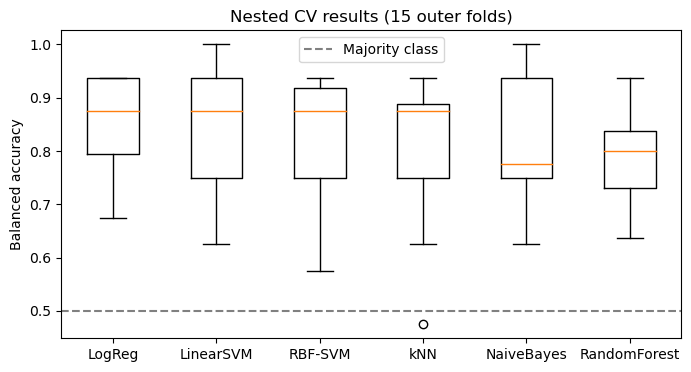

In [10]:
# balanced accuracy of each model over the 15 outer folds
names = list(models.keys())
plt.figure(figsize=(8, 4))
plt.boxplot([folds[folds.model == n].bal_acc for n in names])
plt.xticks(range(1, len(names) + 1), names)
plt.axhline(0.5, linestyle="--", color="grey", label="Majority class")
plt.ylabel("Balanced accuracy")
plt.title("Nested CV results (15 outer folds)")
plt.legend()
plt.savefig("fig_models.png", dpi=200)
plt.show()

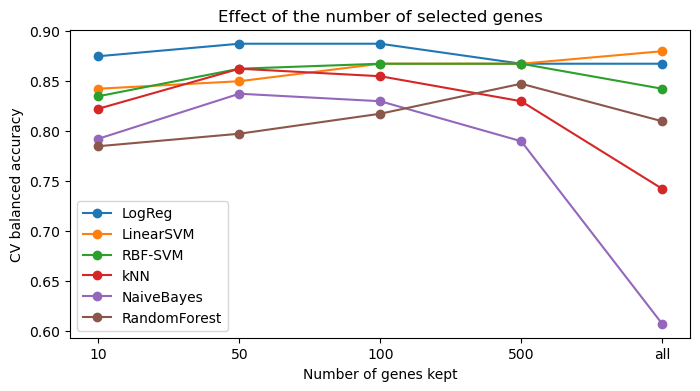

In [11]:
# how the hyperparameters matter. one grid search per model on all the data then look at the scores
# (this is only to describe sensitivity. The performance estimate is the nested CV above)
plt.figure(figsize=(8, 4))
for name, (pipe, grid) in models.items():
    X_used = X + 2 if name == "NaiveBayes" else X
    gs = GridSearchCV(pipe, grid, cv=inner_cv, scoring="balanced_accuracy", n_jobs=-1).fit(X_used, y)
    res = pd.DataFrame(gs.cv_results_)
    res["k"] = res["param_select__k"].astype(str)
    best_per_k = res.groupby("k")["mean_test_score"].max()
    order = ["10", "50", "100", "500", "all"]
    plt.plot(order, best_per_k[order], marker="o", label=name)
plt.xlabel("Number of genes kept")
plt.ylabel("CV balanced accuracy")
plt.title("Effect of the number of selected genes")
plt.legend()
plt.savefig("fig_genes.png", dpi=200)
plt.show()

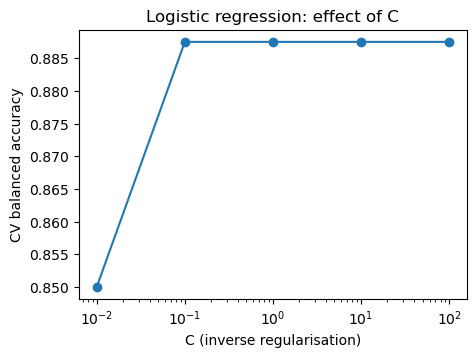

In [12]:
# logistic regression: effect of C
gs = GridSearchCV(*models["LogReg"], cv=inner_cv, scoring="balanced_accuracy", n_jobs=-1).fit(X, y)
res = pd.DataFrame(gs.cv_results_)
best_per_C = res.groupby("param_clf__C")["mean_test_score"].max()
plt.figure(figsize=(5, 3.5))
plt.semilogx(best_per_C.index.astype(float), best_per_C.values, marker="o")
plt.xlabel("C (inverse regularisation)")
plt.ylabel("CV balanced accuracy")
plt.title("Logistic regression: effect of C")
plt.savefig("fig_logreg_C.png", dpi=200)
plt.show()

## 9. Final model

In [13]:
best_name = table[~table.model.isin(baselines)].iloc[0]["model"]
pipe, grid = models[best_name]
X_used = X + 2 if best_name == "NaiveBayes" else X
final = GridSearchCV(pipe, grid, cv=inner_cv, scoring="balanced_accuracy", n_jobs=-1).fit(X_used, y)
print("Best model:", best_name)
print("Final hyperparameters:", final.best_params_)

Best model: LogReg
Final hyperparameters: {'clf__C': 100, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1', 'select__k': 'all'}
